<a href="https://colab.research.google.com/github/jksataya/portfolio-optimization/blob/main/portfolio_optimization_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance scipy pandas numpy matplotlib -q

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from scipy.optimize import minimize

print("Portfolio Optimization Project")
print("Libraries imported successfully!")

Portfolio Optimization Project
Libraries imported successfully!


In [3]:
# Portfolio assets
tickers = [
    "AAPL",  # Apple
    "MSFT",  # Microsoft
    "NVDA",  # NVIDIA
    "AMZN",  # Amazon
    "GOOGL", # Alphabet
    "SPY"    # S&P 500 ETF (benchmark)
]

# Historical data period
start_date = "2021-01-01"
end_date = "2026-01-01"

print("Selected assets:", tickers)

Selected assets: ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'SPY']


In [4]:
# Download adjusted historical prices
data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True
)

# Extract closing prices
prices = data["Close"]

# Remove rows with missing values
prices = prices.dropna()

# Display the first five rows
prices.head()

[*********************100%***********************]  6 of 6 completed


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA,SPY
Date,,,,,,
2021-01-04,125.537102,159.331497,85.492973,207.165237,13.046199,341.588654
2021-01-05,127.089256,160.925507,86.182419,207.365051,13.335954,343.941376
2021-01-06,122.811203,156.919006,85.332001,201.988190,12.549759,345.997620
2021-01-07,127.001907,158.108002,87.880760,207.736237,13.275516,351.138245
2021-01-08,128.098083,159.134995,89.044197,209.001816,13.208610,353.138977


In [5]:
# Calculate daily percentage returns
returns = prices.pct_change().dropna()

# Display daily returns
returns.head()

Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA,SPY
Date,,,,,,
2021-01-05,0.012364,0.010004,0.008064,0.000965,0.022210,0.006888
2021-01-06,-0.033662,-0.024897,-0.009868,-0.025929,-0.058953,0.005978
2021-01-07,0.034123,0.007577,0.029869,0.028457,0.057830,0.014857
2021-01-08,0.008631,0.006496,0.013239,0.006092,-0.005040,0.005698
2021-01-11,-0.023249,-0.021519,-0.023106,-0.009698,0.025966,-0.006741


In [6]:
# Calculate annualized expected returns
annual_returns = returns.mean() * 252

# Calculate annualized volatility
annual_volatility = returns.std() * np.sqrt(252)

# Create summary table
summary = pd.DataFrame({
    "Annual Return": annual_returns,
    "Annual Volatility": annual_volatility
})

# Display results as percentages
summary = summary * 100

summary.round(2)

,Annual Return,Annual Volatility
Ticker,,
AAPL,19.32,27.86
AMZN,13.60,35.11
GOOGL,30.89,31.15
MSFT,20.17,25.71
NVDA,66.95,52.22
SPY,15.20,17.11


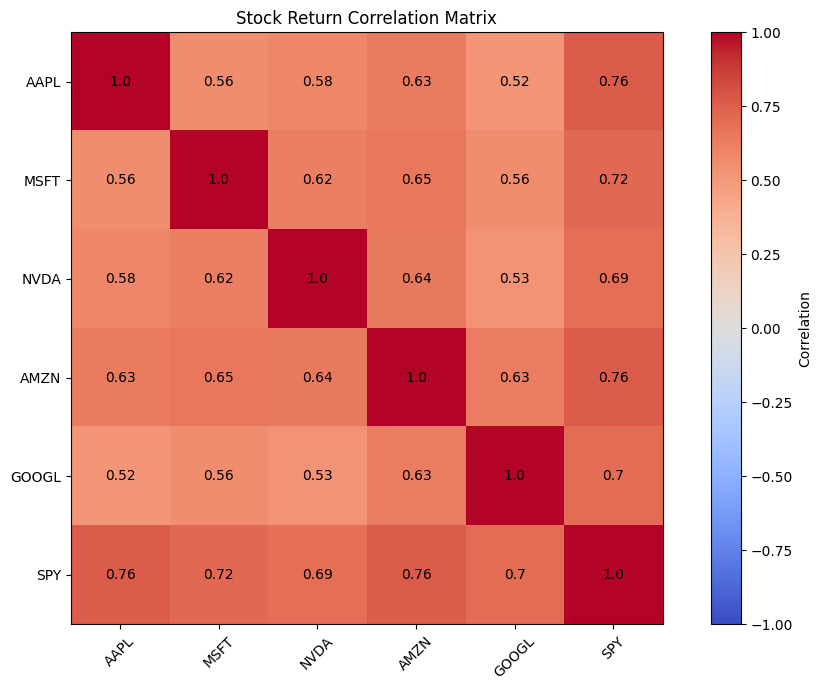

In [7]:
# Calculate correlation between asset returns
correlation_matrix = returns.corr()

# Create correlation heatmap
plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(tickers)),
    tickers,
    rotation=45
)

plt.yticks(
    range(len(tickers)),
    tickers
)

plt.title("Stock Return Correlation Matrix")

# Add correlation values to each cell
for i in range(len(tickers)):
    for j in range(len(tickers)):
        plt.text(
            j, i,
            round(correlation_matrix.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [8]:
# Portfolio Optimization

import numpy as np
import pandas as pd

# Number of assets
num_assets = len(returns.columns)

# Generate random portfolio weights
weights = np.random.random(num_assets)
weights /= np.sum(weights)

# Calculate portfolio annual return
portfolio_return = np.sum(
    returns.mean() * weights * 252
)

# Calculate portfolio annual volatility
portfolio_volatility = np.sqrt(
    np.dot(weights.T, np.dot(returns.cov() * 252, weights))
)

# Calculate Sharpe Ratio
risk_free_rate = 0.04

sharpe_ratio = (
    portfolio_return - risk_free_rate
) / portfolio_volatility

print("Portfolio Weights:", weights.round(4))
print("Annual Return:", round(portfolio_return * 100, 2), "%")
print("Annual Volatility:", round(portfolio_volatility * 100, 2), "%")
print("Sharpe Ratio:", round(sharpe_ratio, 4))

Portfolio Weights: [0.4336 0.0314 0.0266 0.2097 0.2115 0.0872]
Annual Return: 29.34 %
Annual Volatility: 26.99 %
Sharpe Ratio: 0.9388


In [9]:
# Optimize portfolio weights using Monte Carlo simulation

num_portfolios = 10000

results = np.zeros((3, num_portfolios))
all_weights = []

for i in range(num_portfolios):

    weights = np.random.random(num_assets)
    weights /= np.sum(weights)

    portfolio_return = np.sum(
        returns.mean() * weights * 252
    )

    portfolio_volatility = np.sqrt(
        np.dot(weights.T, np.dot(returns.cov() * 252, weights))
    )

    sharpe_ratio = (
        portfolio_return - risk_free_rate
    ) / portfolio_volatility

    results[0, i] = portfolio_return
    results[1, i] = portfolio_volatility
    results[2, i] = sharpe_ratio

    all_weights.append(weights)

# Find portfolio with the highest Sharpe Ratio

best_index = np.argmax(results[2])

best_weights = all_weights[best_index]

print("Optimal Portfolio Weights:")
print(pd.Series(best_weights, index=returns.columns).round(4))

print("Optimal Annual Return:",
      round(results[0, best_index] * 100, 2), "%")

print("Optimal Annual Volatility:",
      round(results[1, best_index] * 100, 2), "%")

print("Maximum Sharpe Ratio:",
      round(results[2, best_index], 4))

Optimal Portfolio Weights:
Ticker
AAPL     0.0463
AMZN     0.0063
GOOGL    0.4760
MSFT     0.0307
NVDA     0.3932
SPY      0.0476
dtype: float64
Optimal Annual Return: 43.35 %
Optimal Annual Volatility: 33.23 %
Maximum Sharpe Ratio: 1.184


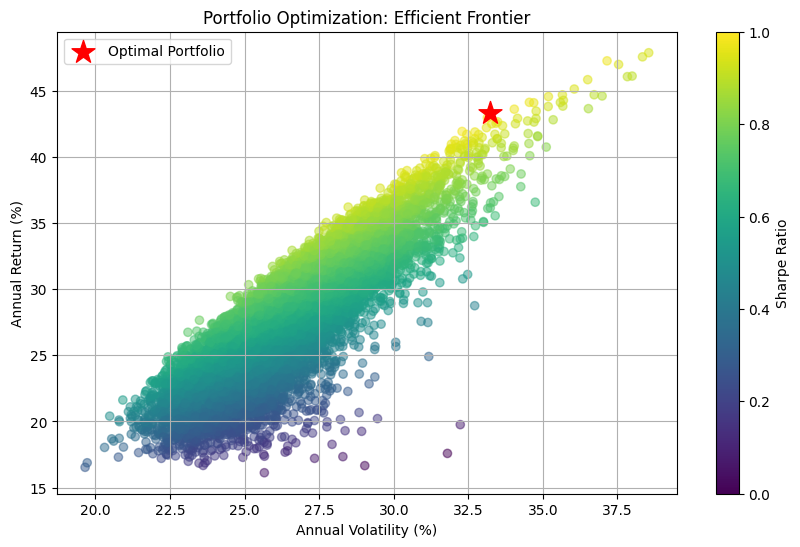

In [10]:
# Plot the Efficient Frontier

plt.figure(figsize=(10, 6))

plt.scatter(
    results[1] * 100,
    results[0] * 100,
    c=results[2],
    cmap="viridis",
    alpha=0.5
)

plt.scatter(
    results[1, best_index] * 100,
    results[0, best_index] * 100,
    color="red",
    marker="*",
    s=300,
    label="Optimal Portfolio"
)

plt.xlabel("Annual Volatility (%)")
plt.ylabel("Annual Return (%)")
plt.title("Portfolio Optimization: Efficient Frontier")
plt.colorbar(label="Sharpe Ratio")
plt.legend()
plt.grid(True)

plt.show()

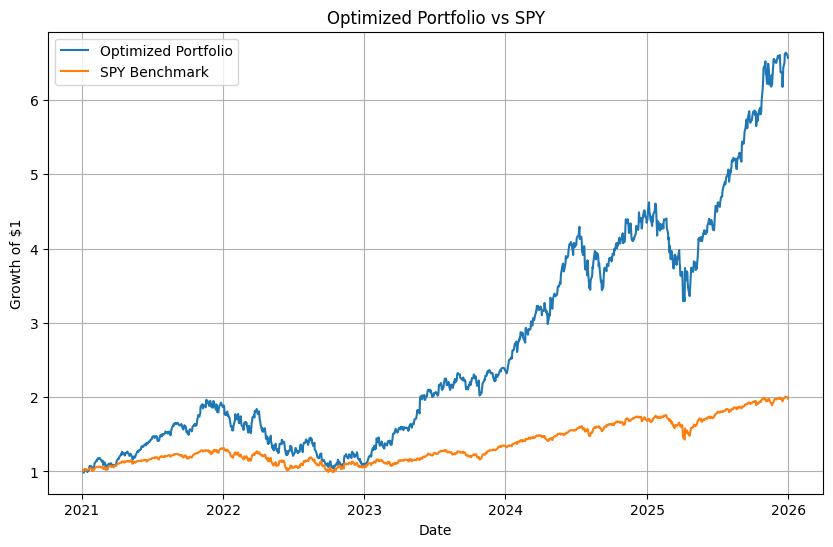

In [11]:
# Compare Optimized Portfolio with SPY

# Calculate optimized portfolio daily returns
optimized_daily_returns = returns.dot(best_weights)

# Calculate SPY daily returns
spy_daily_returns = returns["SPY"]

# Calculate cumulative returns
optimized_cumulative = (1 + optimized_daily_returns).cumprod()
spy_cumulative = (1 + spy_daily_returns).cumprod()

# Plot comparison
plt.figure(figsize=(10, 6))

plt.plot(
    optimized_cumulative,
    label="Optimized Portfolio"
)

plt.plot(
    spy_cumulative,
    label="SPY Benchmark"
)

plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.title("Optimized Portfolio vs SPY")
plt.legend()
plt.grid(True)

plt.show()

# Portfolio Optimization Using Python

## Project Overview
This project analyzes historical stock market data and applies quantitative finance techniques to construct an optimized investment portfolio.

## Objectives
- Analyze historical stock prices and daily returns.
- Calculate annualized returns and volatility.
- Examine correlations between stocks.
- Optimize portfolio weights using the Sharpe Ratio.
- Visualize the Efficient Frontier.
- Compare the optimized portfolio against the S&P 500 (SPY).

## Methodology
The project uses Python, Pandas, NumPy, Matplotlib, and financial data to perform portfolio analysis. Portfolio weights are optimized based on historical returns and risk.

## Key Results
- **Optimal Annual Return:** 43.35%
- **Annual Volatility:** 33.23%
- **Maximum Sharpe Ratio:** 1.184

The optimized portfolio is compared with the SPY benchmark to evaluate its historical performance.

## Conclusion
This project demonstrates how quantitative methods can be used to analyze financial markets and optimize portfolio allocation. The results are based on historical data and do not guarantee future investment performance.